In [17]:
import pandas as pd
import numpy as np

btc = pd.read_csv("../data_clean/btc_clean.csv", index_col="date", parse_dates=True)
rf  = pd.read_csv("../data_clean/rf_daily.csv", index_col=0, parse_dates=True)["rf"]
fc  = pd.read_csv("../data_clean/vol_forecasts.csv", index_col=0, parse_dates=True)
r = btc["ret"]

In [18]:
sig = np.sqrt(fc["ewma"] * 365)                              # tomorrow's forecast, annualised
w_vt = np.minimum(1, 0.30 / sig)                             # vol targeting: 30% ÷ forecast, max 100%
w_fix = 0.30 / (r.loc["2018":"2021"].std() * np.sqrt(365))   # fixed mix, calibrated on training years
print(round(w_fix, 3), round(w_vt.loc["2024":"2025"].mean(), 3))

0.391 0.666


In [19]:
def backtest(w_target, cost=0.0025, start="2022-01-01", end="2025-12-31", lag=1):
    rows, w_drift = [], None
    for t in r.loc[start:end].index:
        w = w_target.loc[t - pd.Timedelta(days=lag)]          # lag=2 means we trade a day late 
        to = w if w_drift is None else abs(w - w_drift)       # how much we trade to reach w
        gross = w * r[t] + (1 - w) * rf[t]                    # BTC part + cash part
        net = gross - cost * to                               # pay trading costs
        w_drift = w * (1 + r[t]) / (w * (1 + r[t]) + (1 - w) * (1 + rf[t]))  # weight after today's move
        rows.append((t, net, to, w))
    return pd.DataFrame(rows, columns=["date", "ret", "to", "w"]).set_index("date")

In [20]:
def metrics(x, a, b):
    d = x.loc[a:b]
    ex = d.ret - rf.loc[a:b]                                  # return above cash
    wealth = (1 + d.ret).cumprod()
    return pd.Series({
        "CAGR": wealth.iloc[-1] ** (365 / len(d)) - 1,
        "vol": d.ret.std() * np.sqrt(365),
        "Sharpe": ex.mean() / ex.std() * np.sqrt(365),
        "max DD": (wealth / wealth.cummax() - 1).min(),
        "turnover/yr": d.to.iloc[1:].sum() / (len(d) / 365),
        "avg weight": d.w.mean(),
    })

strategies = {
    "buy&hold":   pd.Series(1.0, index=r.index),
    "fixed mix":  pd.Series(w_fix, index=r.index),
    "vol target": w_vt,
}
runs = {name: backtest(w) for name, w in strategies.items()}
print(pd.DataFrame({n: metrics(x, "2024", "2025") for n, x in runs.items()}).round(3))

             buy&hold  fixed mix  vol target
CAGR            0.439      0.212       0.270
vol             0.478      0.187       0.306
Sharpe          0.907      0.886       0.788
max DD         -0.321     -0.135      -0.270
turnover/yr     0.000      1.557       4.176
avg weight      1.000      0.391       0.666


In [21]:
for c in [0.001, 0.005]:
    res = {n: metrics(backtest(w, cost=c), "2024", "2025")["Sharpe"] for n, w in strategies.items()}
    print(f"{c*1e4:.0f} bp:", {k: round(v, 3) for k, v in res.items()})
print("2022-25:", {n: round(metrics(x, "2022", "2025")["Sharpe"], 3) for n, x in runs.items()})

10 bp: {'buy&hold': np.float64(0.907), 'fixed mix': np.float64(0.898), 'vol target': np.float64(0.808)}
50 bp: {'buy&hold': np.float64(0.907), 'fixed mix': np.float64(0.865), 'vol target': np.float64(0.754)}
2022-25: {'buy&hold': np.float64(0.488), 'fixed mix': np.float64(0.468), 'vol target': np.float64(0.556)}


<Axes: title={'center': 'Growth of 1 USD, 2024-2025 (net of 25 bp costs)'}, xlabel='date'>

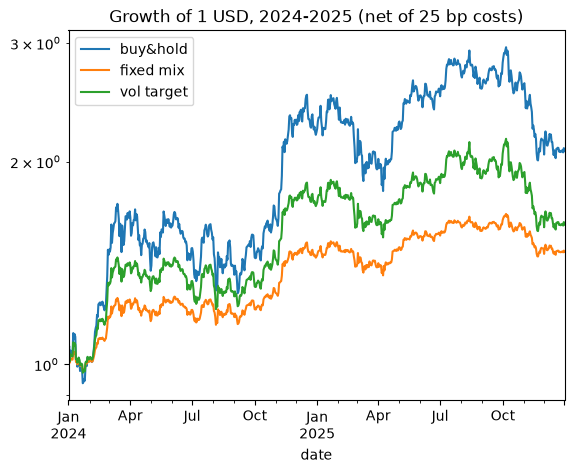

In [22]:
pd.DataFrame({n: (1 + x.loc["2024":"2025", "ret"]).cumprod() for n, x in runs.items()}).plot(
    logy=True, title="Growth of 1 USD, 2024-2025 (net of 25 bp costs)")

In [23]:
def ewma(r, lam):                                        # copied from 04_volatility
    v = (r.loc[:"2017-12-31"]**2).mean(); out = []
    for x in r:
        v = lam*v + (1-lam)*x**2; out.append(v)
    return pd.Series(out, index=r.index)

train_vol = r.loc["2018":"2021"].std() * np.sqrt(365)
def vt(lam=0.97, target=0.30):
    return np.minimum(1, target / np.sqrt(ewma(r.dropna(), lam) * 365))
def fix(target=0.30):
    return pd.Series(target / train_vol, index=r.index)
def sh(x, a="2024", b="2025"):
    return metrics(x, a, b)["Sharpe"]

cases = {
    "base":        (vt(),            fix(),     1),
    "λ 0.94":      (vt(lam=0.94),    fix(),     1),
    "λ 0.98":      (vt(lam=0.98),    fix(),     1),
    "target 25%":  (vt(target=0.25), fix(0.25), 1),
    "target 35%":  (vt(target=0.35), fix(0.35), 1),
    "2-day delay": (vt(),            fix(),     2),
}
rob = {k: {"vol target": sh(backtest(a, lag=l)), "fixed mix": sh(backtest(f, lag=l))}
       for k, (a, f, l) in cases.items()}
print(pd.DataFrame(rob).T.round(3))

             vol target  fixed mix
base              0.788      0.886
λ 0.94            0.770      0.886
λ 0.98            0.790      0.886
target 25%        0.782      0.884
target 35%        0.804      0.888
2-day delay       0.759      0.886


In [24]:
for y in ["2022", "2023", "2024", "2025"]:
    print(y, {n: round(metrics(x, y, y)["Sharpe"], 2) for n, x in runs.items()})

2022 {'buy&hold': np.float64(-1.33), 'fixed mix': np.float64(-1.35), 'vol target': np.float64(-1.49)}
2023 {'buy&hold': np.float64(2.25), 'fixed mix': np.float64(2.23), 'vol target': np.float64(2.13)}
2024 {'buy&hold': np.float64(1.67), 'fixed mix': np.float64(1.65), 'vol target': np.float64(1.74)}
2025 {'buy&hold': np.float64(-0.04), 'fixed mix': np.float64(-0.06), 'vol target': np.float64(-0.21)}


In [25]:
ex_vt = (runs["vol target"].loc["2024":"2025", "ret"] - rf.loc["2024":"2025"]).values
ex_fx = (runs["fixed mix"].loc["2024":"2025", "ret"] - rf.loc["2024":"2025"]).values
def sr(x): return x.mean() / x.std() * np.sqrt(365)

rng = np.random.default_rng(42)                 # fixed seed, so you get my numbers
n, B, diffs = len(ex_vt), 20, []
for _ in range(5000):                           # 5,000 "alternative histories"
    starts = rng.integers(0, n - B + 1, int(np.ceil(n / B)))
    ix = np.concatenate([np.arange(s, s + B) for s in starts])[:n]
    diffs.append(sr(ex_vt[ix]) - sr(ex_fx[ix]))
print(round(sr(ex_vt) - sr(ex_fx), 3), np.percentile(diffs, [2.5, 97.5]).round(2))

-0.098 [-0.3  0.1]
